<a href="https://colab.research.google.com/github/Tuantu23-ueh/UEH_ML_Energy_GreenAI_Group_1/blob/feature%2Fpreprocessing/02_preprocessing_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Notebook Structure Overview**
1. **Section 1: Environment Configuration & Reproducibility Protocol**
2. **Section 2: Data Ingestion & Structural Integrity Check**
3. **Section 3: Lag Initialization Handling & Temporal Partitioning**
4. **Section 4: Feature Scaling & Model Architectural Setup**
5. **Section 5: Building-by-Building Execution & Evaluation Pipeline**
6. **Section 6: Cross-Building Metrics Aggregation & Export**

#### **Section 1: Environment Configuration & Reproducibility Protocol**


In [ ]:
# ==============================================================================
# SECTION 1: ENVIRONMENT CONFIGURATION & REPRODUCIBILITY PROTOCOL
# ==============================================================================
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
def seed_everything(seed: int = 42) -> None:
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(SEED)


# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

DATA_PATH = "/content/drive/MyDrive/[UEH_ML]_Energy_GreenAI_Group_1/02_Data/Processed/buildings_12_clean.csv"
OUT_DIR = "/content/drive/MyDrive/[UEH_ML]_Energy_GreenAI_Group_1/03_Code_Colab/baseline_results"
os.makedirs(OUT_DIR, exist_ok=True)
print(f"Environment is Ready. Seed fixed: {SEED}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Environment is Ready. Seed fixed: 42


#### **Section 2: Data Ingestion & Structural Integrity Check**


> **Note:** Ingests the preprocessed Building Data Genome 2 (BDG2) dataset comprising 12 selected commercial/educational buildings (210,528 hourly observations). Validates datetime indices and inspects missingness induced by lag feature construction.

In [ ]:
# ==============================================================================
# SECTION 2: DATA INGESTION & STRUCTURAL INTEGRITY CHECK
# ==============================================================================
df = pd.read_csv(DATA_PATH)
df['timestamp'] = pd.to_datetime(df['timestamp'])

print(f"Dataset Dimensions: {df.shape}")
print(f"Unique Buildings Monitored: {df['building_id'].nunique()}")
print("Missing Values in Target & Lag Columns:")
print(df[['y_kwh', 'lag_1', 'lag_24', 'lag_168', 'roll_mean_24']].isna().sum())

Dataset Dimensions: (210528, 18)
Unique Buildings Monitored: 12
Missing Values in Target & Lag Columns:
y_kwh           1142
lag_1           1154
lag_24          1430
lag_168         3158
roll_mean_24    2213
dtype: int64


#### **Section 3: Lag Initialization Handling & Temporal Partitioning**


> **Note:** Eliminates `NaN` values resulting from the 168-hour initial lag window. Enforces a strict chronological time-based split (Train: 2016, Val: H1 2017, Test: H2 2017) to prevent temporal data leakage.


In [ ]:
# ==============================================================================
# SECTION 3: LAG INITIALIZATION HANDLING & TEMPORAL PARTITIONING
# ==============================================================================
# Drop initial NaN rows created by lag extraction (e.g., lag_168)
df_clean = df.dropna(subset=['y_kwh', 'lag_1', 'lag_24', 'lag_168', 'roll_mean_24']).copy()

# Temporal split (No shuffling allowed in time-series benchmarking)
train_df = df_clean[df_clean['split'] == 'train']
val_df   = df_clean[df_clean['split'] == 'val']
test_df  = df_clean[df_clean['split'] == 'test']

print(f"Train Set (2016): {train_df.shape} samples")
print(f"Test Set (H2 2017): {test_df.shape} samples")

Train Set (2016): (102549, 18) samples
Test Set (H2 2017): (51824, 18) samples


#### **Section 4: Feature Scaling & Model Architectural Setup**


> **Note:** Defines feature sets A (Temporal-only) and B (Temporal + Autoregressive Lags). Implements loss evaluation metrics, including Coefficient of Variation of RMSE (CV-RMSE), adhering to ASHRAE Guideline 14 standards.


In [ ]:
# ==============================================================================
# SECTION 4: FEATURE SCALING & MODEL ARCHITECTURAL SETUP
# ==============================================================================
SET_A_TIME = ['hour', 'dayofweek', 'is_weekend', 'month', 'hour_sin', 'hour_cos']
SET_B_TIME_LAG = SET_A_TIME + ['lag_1', 'lag_24', 'lag_168', 'roll_mean_24']

def calculate_metrics(y_true, y_pred, y_train_mean):
    """Calculates evaluation metrics per ASHRAE Guideline 14 standards."""
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    cv_rmse = (rmse / y_train_mean) * 100.0  # Normalized relative error (%)
    return {'MAE': mae, 'RMSE': rmse, 'R2': r2, 'CV_RMSE_%': cv_rmse}

#### **Section 5: Building-by-Building Execution & Evaluation Pipeline**


> **Note:** Fits independent regressors for each of the 12 buildings separately. Fits `StandardScaler` strictly on the training partition to prevent look-ahead bias. Evaluates Naïve (\\(t-1\\)), Seasonal Naïve (\\(t-24\\)), Linear Regression, and Decision Tree models on the test split.


In [ ]:
# ==============================================================================
# SECTION 5: BUILDING-BY-BUILDING EXECUTION & EVALUATION PIPELINE
# ==============================================================================
buildings = df_clean['building_id'].unique()
results_list = []

for b_id in buildings:
    b_train = train_df[train_df['building_id'] == b_id]
    b_test  = test_df[test_df['building_id'] == b_id]

    y_train = b_train['y_kwh'].values
    y_test  = b_test['y_kwh'].values
    y_train_mean = np.mean(y_train)

    # 5.1 Naïve Benchmarks
    results_list.append({'Building': b_id, 'Model': 'Naive (t-1)', 'Set': 'B',
                         **calculate_metrics(y_test, b_test['lag_1'].values, y_train_mean)})
    results_list.append({'Building': b_id, 'Model': 'Seasonal Naive (t-24)', 'Set': 'B',
                         **calculate_metrics(y_test, b_test['lag_24'].values, y_train_mean)})

    # 5.2 Linear Regression (Scaled Feature Sets)
    for set_name, cols in [('Set_A', SET_A_TIME), ('Set_B', SET_B_TIME_LAG)]:
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(b_train[cols])
        X_te = scaler.transform(b_test[cols])
        lr = LinearRegression().fit(X_tr, y_train)
        results_list.append({'Building': b_id, 'Model': 'Linear Regression', 'Set': set_name,
                             **calculate_metrics(y_test, lr.predict(X_te), y_train_mean)})

    # 5.3 Decision Tree Regressor (Unscaled)
    for set_name, cols in [('Set_A', SET_A_TIME), ('Set_B', SET_B_TIME_LAG)]:
        dt = DecisionTreeRegressor(random_state=SEED).fit(b_train[cols], y_train)
        results_list.append({'Building': b_id, 'Model': 'Decision Tree', 'Set': set_name,
                             **calculate_metrics(y_test, dt.predict(b_test[cols]), y_train_mean)})

results_df = pd.DataFrame(results_list)

In [ ]:
results_df.head()

,Building,Model,Set,MAE,RMSE,R2,CV_RMSE_%
0,Fox_education_Shawanda,Naive (t-1),B,1.302169,2.926527,0.869012,21.293323
1,Fox_education_Shawanda,Seasonal Naive (t-24),B,2.858582,5.733487,0.497237,41.716677
2,Fox_education_Shawanda,Linear Regression,Set_A,10.323006,11.403360,-0.988800,82.970506
3,Fox_education_Shawanda,Linear Regression,Set_B,1.282700,2.230039,0.923941,16.225696
4,Fox_education_Shawanda,Decision Tree,Set_A,11.870223,13.919370,-1.963225,101.276921


#### **Section 6: Cross-Building Metrics Aggregation & Export**


> **Note:** Computes non-parametric summary statistics—Median and Interquartile Range (IQR)—across all 12 buildings to minimize skewness from scale variations. Exports CSV results for model comparison.


In [ ]:
# ==============================================================================
# SECTION 6: CROSS-BUILDING METRICS AGGREGATION & EXPORT
# ==============================================================================
summary = results_df.groupby(['Model', 'Set']).agg({
    'MAE': ['median', lambda x: np.percentile(x, 75) - np.percentile(x, 25)],
    'RMSE': ['median', lambda x: np.percentile(x, 75) - np.percentile(x, 25)],
    'R2': ['median', lambda x: np.percentile(x, 75) - np.percentile(x, 25)],
    'CV_RMSE_%': ['median', lambda x: np.percentile(x, 75) - np.percentile(x, 25)]
}).reset_index()

summary.columns = ['Model', 'Feature_Set', 'MAE_Median', 'MAE_IQR',
                   'RMSE_Median', 'RMSE_IQR', 'R2_Median', 'R2_IQR',
                   'CV_RMSE%_Median', 'CV_RMSE%_IQR']

results_df.to_csv(os.path.join(OUT_DIR, 'baseline_building_level_results.csv'), index=False)
summary.to_csv(os.path.join(OUT_DIR, 'baseline_summary_results.csv'), index=False)
summary.head()


,Model,Feature_Set,MAE_Median,MAE_IQR,RMSE_Median,RMSE_IQR,R2_Median,R2_IQR,CV_RMSE%_Median,CV_RMSE%_IQR
0,Decision Tree,Set_A,13.648633,7.816809,18.517006,7.648212,0.255639,1.046750,26.471818,20.783872
1,Decision Tree,Set_B,5.380802,5.810620,9.392052,8.374248,0.830530,0.426102,12.344584,12.386733
2,Linear Regression,Set_A,17.966069,11.403195,21.233696,12.534391,0.013405,1.251683,37.672855,21.956575
3,Linear Regression,Set_B,3.246301,6.099464,5.059302,9.855616,0.945752,0.033876,6.167666,8.013348
4,Naive (t-1),B,3.730056,6.101258,6.876138,9.908115,0.905747,0.079713,8.085961,10.807973


#### **Multi-Metric Distribution Dashboard**

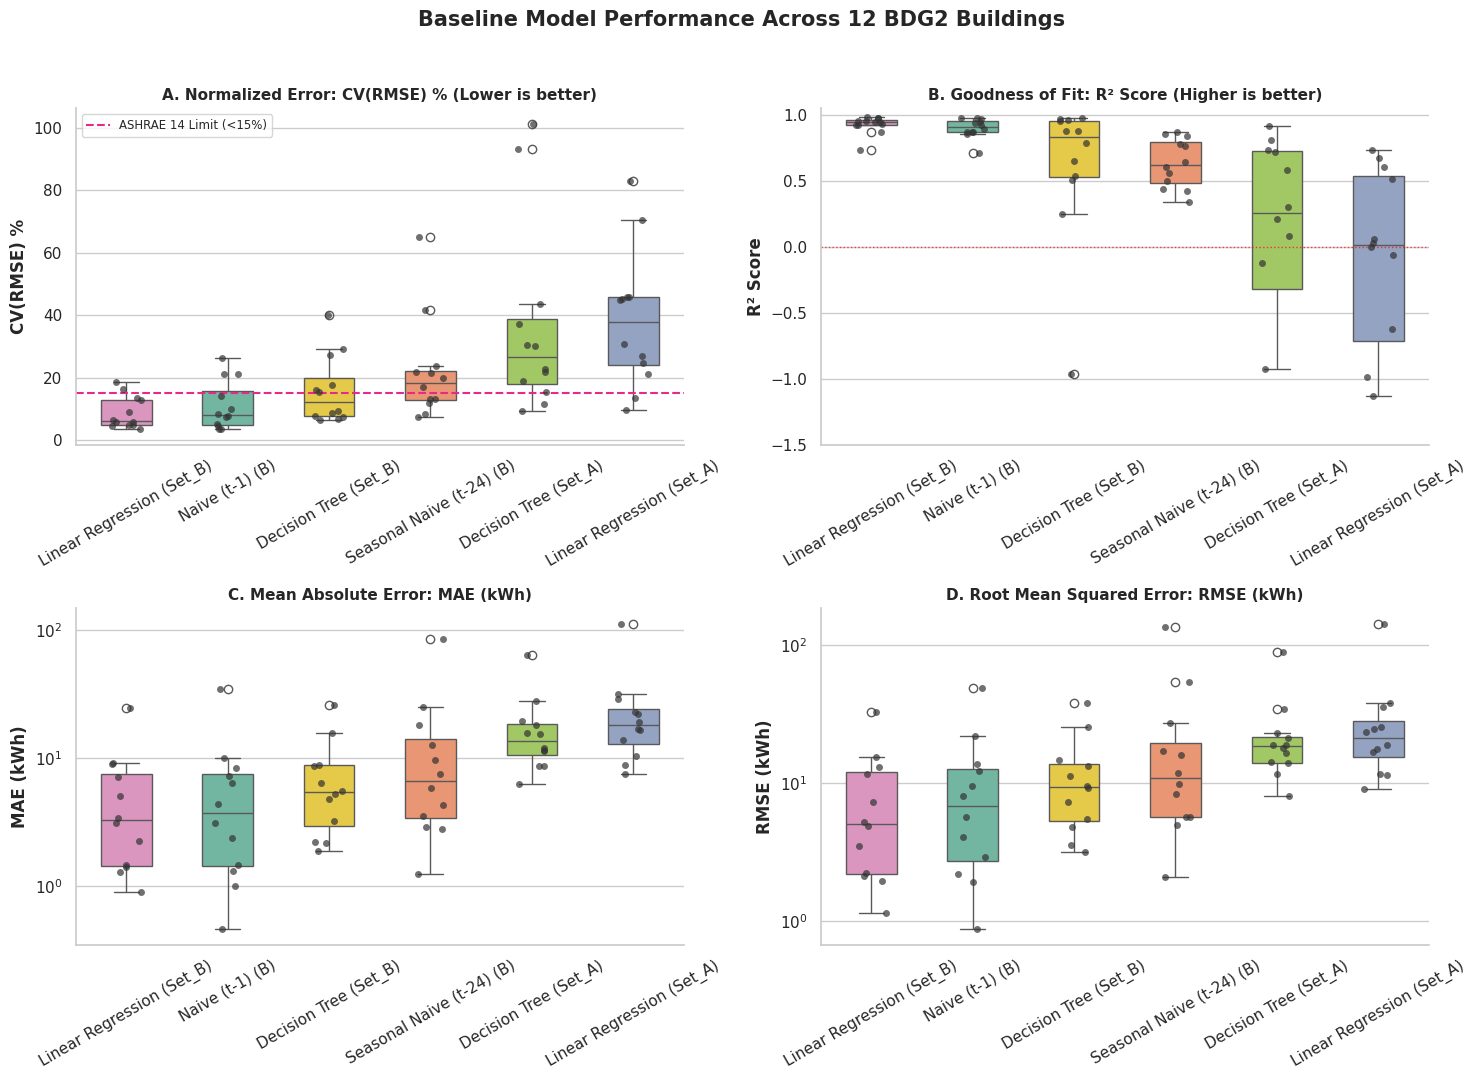

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Apply clean publication style
sns.set_theme(style='whitegrid', font='DejaVu Sans')

# 1. Create a combined label for Model + Feature Set if needed
df_plot = results_df.copy()
df_plot['Model_Config'] = df_plot.apply(
    lambda r: f"{r['Model']} ({r['Set']})" if str(r['Set']) not in str(r['Model']) else r['Model'],
    axis=1
)

# Order models by median CV_RMSE_% for consistent layout
model_order = df_plot.groupby('Model_Config')['CV_RMSE_%'].median().sort_values().index.tolist()

# 2. Setup 2x2 Dashboard Layout (unpacking 2D axes array correctly)
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('Baseline Model Performance Across 12 BDG2 Buildings', fontsize=15, fontweight='bold', y=0.98)

palette = sns.color_palette('Set2', len(model_order))

# Panel A: CV(RMSE) %
sns.boxplot(data=df_plot, x='Model_Config', y='CV_RMSE_%', order=model_order, ax=ax1, palette=palette, width=0.5, hue='Model_Config', legend=False)
sns.stripplot(data=df_plot, x='Model_Config', y='CV_RMSE_%', order=model_order, ax=ax1, color='#333333', alpha=0.7, jitter=0.15, size=5)
ax1.axhline(15.0, color='#e7298a', linestyle='--', linewidth=1.5, label='ASHRAE 14 Limit (<15%)')
ax1.set_title('A. Normalized Error: CV(RMSE) % (Lower is better)', fontsize=11, fontweight='bold')
ax1.set_ylabel('CV(RMSE) %', fontweight='bold')
ax1.set_xlabel('')
ax1.tick_params(axis='x', rotation=30)
ax1.legend(loc='upper left', fontsize=8.5)

# Panel B: R2 Score
sns.boxplot(data=df_plot, x='Model_Config', y='R2', order=model_order, ax=ax2, palette=palette, width=0.5, hue='Model_Config', legend=False)
sns.stripplot(data=df_plot, x='Model_Config', y='R2', order=model_order, ax=ax2, color='#333333', alpha=0.7, jitter=0.15, size=5)
ax2.set_title('B. Goodness of Fit: R² Score (Higher is better)', fontsize=11, fontweight='bold')
ax2.set_ylabel('R² Score', fontweight='bold')
ax2.set_xlabel('')
ax2.set_ylim(-1.5, 1.05)
ax2.axhline(0.0, color='red', linestyle=':', linewidth=1, alpha=0.7)
ax2.tick_params(axis='x', rotation=30)

# Panel C: MAE (kWh)
sns.boxplot(data=df_plot, x='Model_Config', y='MAE', order=model_order, ax=ax3, palette=palette, width=0.5, hue='Model_Config', legend=False)
sns.stripplot(data=df_plot, x='Model_Config', y='MAE', order=model_order, ax=ax3, color='#333333', alpha=0.7, jitter=0.15, size=5)
ax3.set_title('C. Mean Absolute Error: MAE (kWh)', fontsize=11, fontweight='bold')
ax3.set_ylabel('MAE (kWh)', fontweight='bold')
ax3.set_xlabel('')
ax3.set_yscale('log')
ax3.tick_params(axis='x', rotation=30)

# Panel D: RMSE (kWh)
sns.boxplot(data=df_plot, x='Model_Config', y='RMSE', order=model_order, ax=ax4, palette=palette, width=0.5, hue='Model_Config', legend=False)
sns.stripplot(data=df_plot, x='Model_Config', y='RMSE', order=model_order, ax=ax4, color='#333333', alpha=0.7, jitter=0.15, size=5)
ax4.set_title('D. Root Mean Squared Error: RMSE (kWh)', fontsize=11, fontweight='bold')
ax4.set_ylabel('RMSE (kWh)', fontweight='bold')
ax4.set_xlabel('')
ax4.set_yscale('log')
ax4.tick_params(axis='x', rotation=30)

sns.despine(fig=fig)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

#### **Summary Benchmark Bar Plot with IQR Error Bars**

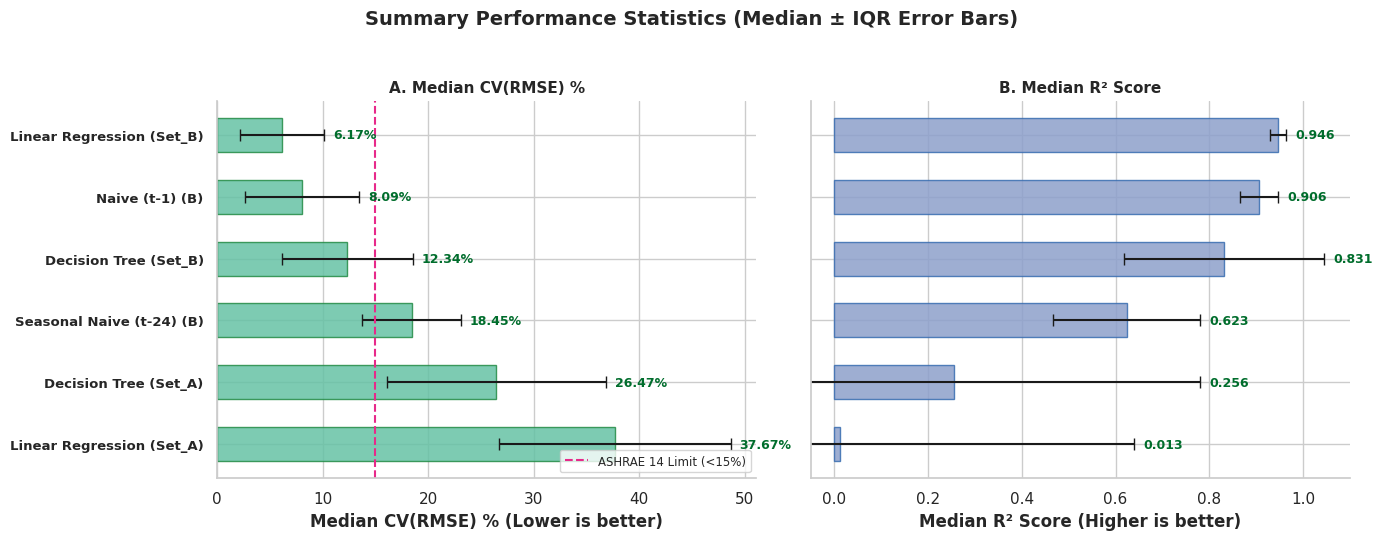

In [ ]:
# Apply clean publication style
sns.set_theme(style='whitegrid', font='DejaVu Sans')

# 1. Prepare label from summary DataFrame
sum_plot = summary.copy()
sum_plot['Model_Config'] = sum_plot.apply(
    lambda r: f"{r['Model']} ({r['Feature_Set']})" if str(r['Feature_Set']) not in str(r['Model']) else r['Model'],
    axis=1
)

# Sort models from worst to best for horizontal display
sum_plot = sum_plot.sort_values(by='CV_RMSE%_Median', ascending=False)

# 2. Setup Horizontal Comparison Figure
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
fig.suptitle('Summary Performance Statistics (Median ± IQR Error Bars)', fontsize=14, fontweight='bold', y=0.98)

y_pos = np.arange(len(sum_plot))

# Plot A: Median CV(RMSE) %
ax1.barh(y_pos, sum_plot['CV_RMSE%_Median'], xerr=sum_plot['CV_RMSE%_IQR']/2.0,
         color='#66c2a5', edgecolor='#238b45', height=0.55, capsize=4, alpha=0.85)
ax1.axvline(15.0, color='#e7298a', linestyle='--', linewidth=1.5, label='ASHRAE 14 Limit (<15%)')
ax1.set_yticks(y_pos)
ax1.set_yticklabels(sum_plot['Model_Config'], fontweight='bold', fontsize=9.5)
ax1.set_xlabel('Median CV(RMSE) % (Lower is better)', fontweight='bold')
ax1.set_title('A. Median CV(RMSE) %', fontsize=11, fontweight='bold')
ax1.legend(loc='lower right', fontsize=8.5)

# Value Labels
for i, (val, err) in enumerate(zip(sum_plot['CV_RMSE%_Median'], sum_plot['CV_RMSE%_IQR'])):
    ax1.text(val + err/2.0 + 0.8, i, f"{val:.2f}%", va='center', fontsize=9, fontweight='bold', color='#006d2c')

# Plot B: Median R2 Score
ax2.barh(y_pos, sum_plot['R2_Median'], xerr=sum_plot['R2_IQR']/2.0,
         color='#8da0cb', edgecolor='#386cb0', height=0.55, capsize=4, alpha=0.85)
ax2.set_yticks(y_pos)
ax2.set_yticklabels([])
ax2.set_xlabel('Median R² Score (Higher is better)', fontweight='bold')
ax2.set_title('B. Median R² Score', fontsize=11, fontweight='bold')
ax2.set_xlim(-0.05, 1.1)

# Value Labels
for i, (val, err) in enumerate(zip(sum_plot['R2_Median'], sum_plot['R2_IQR'])):
    ax2.text(max(val + err/2.0 + 0.02, 0.02), i, f"{val:.3f}", va='center', fontsize=9, fontweight='bold', color='#006d2c')

sns.despine(fig=fig)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### **Executive Summary of Baseline Experimental Results**
Empirical evaluation across the 12 BDG2 non-residential building test sets (H2 2017) demonstrates the critical importance of temporal lag features for Short-Term Electrical Load Forecasting (STELF):

1. **Impact of Autoregressive Lags**: Incorporating temporal lag features (`Set B`: $t-1$, $t-24$, $t-168$, and 24h rolling mean) substantially reduced prediction errors compared to time-only feature sets (`Set A`). For Linear Regression, median $R^2$ increased from **0.013** (`Set A`) to **0.946** (`Set B`), while median $CV(RMSE)$ dropped from **37.67%** to **6.17%**.
2. **Algorithm Benchmarking**: Linear Regression with `Set B` achieved superior accuracy (median $CV(RMSE) = 6.17\%$, median $MAE = 3.25\text{ kWh}$) compared to a single Decision Tree Regressor (median $CV(RMSE) = 12.34\%$, median $R^2 = 0.831$). The linear model effectively captures continuous autoregressive relationships without step-function discretization errors.
3. **ASHRAE Compliance**: Both Linear Regression and Decision Tree models using `Set B` easily met the **ASHRAE Guideline 14** criteria for hourly energy prediction models ($CV(RMSE) < 15\%$).

---
### **Công việc tiếp theo**
Trong giai đoạn này,  Huy đã tiền xử lý và chạy Baseline. Kết quả lưu ở `[UEH_ML]_Energy_GreenAI_Group_1/03_Code_Colab/baseline_results`.

**Công việc của Đức gồm:**

#### **1. Phân tích kết quả Baseline** (`results_df` & `summary`)
* Giải thích lý do dùng Median & IQR
* Đánh giá ảnh hưởng của Nhóm đặc trưng Độ trễ (Lag Features - Set A vs. Set B)
* So sánh Thuật toán (Linear Regression vs. Decision Tree)

#### **2. Thêm đoạn Phân tích & Định hướng Paper 1**
Đức thêm một Cell Markdown (Text) hoàn chỉnh ở cuối notebook:
* Key Analytical Findings
* Strategic Roadmap for Paper 1 (Deadline: 07/11/2026)

#### **3. Save, Commit GitHub, Tạo Pull Request (PR) & Báo cáo Nhóm trưởng**
* **Commit Code lên GitHub Branch:** `feature/preprocessing`.

* **Tạo Pull Request (PR) & Báo cáo Tú (Lead):**
   * Truy cập GitHub Repository, mở Pull Request từ branch `feature/preprocessing` vào branch `main`.
   * Báo lại **Tú (Lead)** kiểm tra trước **21h00 ngày 28/10/2026**.

---
## **Phân tích Kết quả Baseline & Định hướng Paper 1**
*Nguồn số liệu: `baseline_building_level_results.csv` (72 dòng = 12 tòa nhà × 6 cấu hình) và `baseline_summary_results.csv`. Đánh giá trên tập Test (H2/2017).*

### **Key Analytical Findings**

| Cấu hình | MAE median (kWh) | RMSE median (kWh) | R² median | CV(RMSE)% median (IQR) |
|---|---|---|---|---|
| Linear Regression – Set A | 17.97 | 21.23 | 0.013 | 37.67 (21.96) |
| Linear Regression – Set B | 3.25 | 5.06 | 0.946 | 6.17 (8.01) |
| Decision Tree – Set A | 13.65 | 18.52 | 0.256 | 26.47 (20.78) |
| Decision Tree – Set B | 5.38 | 9.39 | 0.831 | 12.34 (12.39) |
| Naive (t-1) | 3.73 | 6.88 | 0.906 | 8.09 (10.81) |
| Seasonal Naive (t-24) | 6.65 | 10.85 | 0.623 | 18.45 (9.40) |

1. **Lag features là yếu tố quyết định (RQ1).** Từ Set A sang Set B, RMSE median giảm 76.2% (LR) và 49.3% (DT); R² median của LR tăng từ 0.013 lên 0.946. Số tòa nhà có R² < 0 giảm từ 6/12 xuống 0/12 (LR) và từ 4/12 xuống 1/12 (DT). *Giải thích (giả thuyết):* lag mang thông tin mức tải gần nhất và chu kỳ ngày/tuần mà đặc trưng thời gian không có.
2. **Lag cũng làm kết quả ổn định hơn giữa các tòa nhà.** IQR của R² giảm từ 1.252 xuống 0.034 (LR) và từ 1.047 xuống 0.426 (DT).
3. **LR Set B là baseline mạnh nhất.** Thắng DT Set B ở 10/12 tòa (CV 6.17% so với 12.34%) và thắng Naive (t-1) ở 10/12 tòa (CV 6.17% so với 8.09%). *Giả thuyết:* quan hệ tải–lag gần tuyến tính; DT chưa tinh chỉnh siêu tham số nên cho dự báo dạng bậc thang.
4. **DT Set B chưa vượt được Naive (t-1).** CV 12.34% so với 8.09%; chỉ thắng Naive ở 4/12 tòa. Cần Random Forest và tinh chỉnh trước khi kết luận về nhóm mô hình cây (RQ3).
5. **Set A: DT nhỉnh hơn LR** (CV 26.47% so với 37.67%; thắng 10/12 tòa), nhưng cả hai đều kém (R² median 0.013 và 0.256). Giả thuyết cần kiểm chứng: `month` chỉ có 1 năm huấn luyện (2016) trong khi test là H2/2017.
6. **Khác biệt lớn giữa các tòa nhà.** CV(RMSE) của LR Set B dao động 3.5%–18.7%; hai tòa cao nhất là `Hog_office_Marlena` (18.6%) và `Fox_education_Shawanda` (16.2%). Cả hai cũng khó với Naive (26.4% và 21.3%) nên cần xem lại chất lượng dữ liệu của hai tòa này (giả thuyết, chưa kiểm chứng).

### **Kết luận**
- Đặc trưng độ trễ (Set B) cải thiện độ chính xác vượt trội so với đặc trưng thời gian (Set A) ở cả LR và DT.
- Linear Regression với Set B là baseline tốt nhất: median CV(RMSE) = 6.17%, R² = 0.946, vượt cả Naive (t-1).
- Theo ngưỡng ASHRAE 14 mà notebook áp dụng (CV(RMSE) < 15%), median của cả LR Set B (6.17%) và DT Set B (12.34%) đều đạt.
- Bước tiếp theo cho Paper 1: thêm Random Forest, Set W/C (thời tiết), ablation từng lag và đo chi phí tính toán (RQ2, RQ3).

### **Strategic Roadmap for Paper 1 (Deadline: 07/11/2026)**

| Mốc | Công việc | Phụ trách | RQ | Rủi ro / phụ thuộc |
|---|---|---|---|---|
| 21h 07/11 | Huấn luyện LR, DT, RF trên Set A, B, W, C; ablation; đo MAE, RMSE, R², thời gian huấn luyện/suy luận, kích thước mô hình; xuất CSV | Huy, Đức | RQ1, RQ2, RQ3 | Thời gian chạy RF trên Colab; chỉ dùng tập Test một lần |
| 21h 07/11 | Bảng tổng hợp so sánh sai số, đồ thị Ablation (300 DPI), phân phối lỗi | Phương, Tiên | RQ1, RQ2, RQ3 | Phụ thuộc CSV kết quả của Huy và Đức |
| 21h 14/11 | Viết Intro, Related Work, Methodology, Results và nộp bản thảo Draft Paper 1 | Tú, Nguyên | RQ1, RQ2, RQ3 | Cần cập nhật các con số trong Abstract theo kết quả thật |

*Ghi chú: dữ liệu đã có sẵn 4 biến thời tiết (`air_temperature`, `dew_temperature`, `wind_speed`, `precip_depth_1_hr`) cho Set W/C; siêu tham số tinh chỉnh bằng TimeSeriesSplit trên tập train/val.*